# EXPLANATORY DATA ANALYSIS

In [1]:
from pathlib import Path
import sys

# Add path to project root
project_root = Path().cwd().parents[0]
sys.path.insert(0, str(project_root))

# Import self made EDA functions
from scripts.explanatory_data_analysis import (
    fetch_dataset_and_turn_into_dataframe_and_convert_column_names_to_lowercase,
    extract_categorical_columns,
    extract_numerical_columns,
    dataset_structure_and_basic_inspection,
    dataset_quality_inspection,
    descriptive_statistics,
    target_variable_analysis,
    univariate_analysis,
    bevariate_analysis,
    correlation_and_feature_relevance,
)

In [2]:
# Dataset path
data_path = project_root / "data" / "raw" / "student_mental_health.csv"

# Store dataframe
df = fetch_dataset_and_turn_into_dataframe_and_convert_column_names_to_lowercase(
    data_path
)
# Extract cetegorical columns
categorical_columns = extract_categorical_columns(df)
print(f"Categorical columns: {categorical_columns}")
print("=" * 30)
# Extract numerical columns
numerical_columns = extract_numerical_columns(df)
print(f"Numerical columns: {numerical_columns}")

Categorical columns:      student_id  gender physical_activity part_time_job diet_quality  \
0       STU0001    Male          Moderate            No         Poor   
1       STU0002    Male               Low           Yes      Average   
2       STU0003    Male               Low            No      Average   
3       STU0004    Male              High            No      Average   
4       STU0005  Female          Moderate           Yes          NaN   
...         ...     ...               ...           ...          ...   
1995    STU1996    Male              High            No      Average   
1996    STU1997    Male          Moderate           Yes         Poor   
1997    STU1998  Female               Low           Yes          NaN   
1998    STU1999    Male          Moderate            No         Good   
1999    STU2000  Female              High            No      Average   

     previous_mental_health_history mental_health_risk  
0                                No               High  


In [3]:
# Dataset structure and basic inspection
dataset_structure_and_basic_inspection(df)

DATASET SHAPE: 
2000 rows, 17 columns
COLUMN NAMES: 
['student_id', 'age', 'gender', 'year_of_study', 'sleep_hours', 'study_hours_per_week', 'gpa', 'social_media_hours', 'screen_time_hours', 'physical_activity', 'financial_stress', 'family_support', 'attendance_rate', 'part_time_job', 'diet_quality', 'previous_mental_health_history', 'mental_health_risk']
DATA TYPES: 
student_id                            str
age                                 int64
gender                                str
year_of_study                       int64
sleep_hours                       float64
study_hours_per_week              float64
gpa                               float64
social_media_hours                float64
screen_time_hours                 float64
physical_activity                     str
financial_stress                  float64
family_support                    float64
attendance_rate                   float64
part_time_job                         str
diet_quality                          str

,student_id,age,gender,year_of_study,sleep_hours,study_hours_per_week,gpa,social_media_hours,screen_time_hours,physical_activity,financial_stress,family_support,attendance_rate,part_time_job,diet_quality,previous_mental_health_history,mental_health_risk
0,STU0001,22,Male,3,6.6,17.6,2.91,6.9,7.5,Moderate,8.5,4.0,78.0,No,Poor,No,High
1,STU0002,21,Male,4,5.6,22.4,2.92,7.6,11.5,Low,4.5,5.3,85.4,Yes,Average,No,Medium
2,STU0003,22,Male,5,7.1,28.1,2.68,6.5,8.9,Low,4.8,6.1,79.5,No,Average,No,Medium
3,STU0004,24,Male,1,4.5,14.8,2.23,5.5,7.6,High,3.7,8.0,73.9,No,Average,Yes,High
4,STU0005,20,Female,1,6.7,17.2,2.69,4.3,7.0,Moderate,8.0,7.4,99.8,Yes,NaN,No,Medium


LAST 5 ROWS: 



,student_id,age,gender,year_of_study,sleep_hours,study_hours_per_week,gpa,social_media_hours,screen_time_hours,physical_activity,financial_stress,family_support,attendance_rate,part_time_job,diet_quality,previous_mental_health_history,mental_health_risk
1995,STU1996,23,Male,2,7.5,20.3,1.89,7.3,10.7,High,8.2,6.3,80.9,No,Average,No,Medium
1996,STU1997,21,Male,2,6.4,16.8,2.14,4.6,5.8,Moderate,4.6,3.5,76.9,Yes,Poor,No,High
1997,STU1998,19,Female,1,4.5,13.1,2.54,7.5,10.0,Low,6.7,8.1,87.9,Yes,NaN,No,High
1998,STU1999,21,Male,3,8.1,22.3,2.62,4.5,6.6,Moderate,6.5,8.4,100.0,No,Good,No,Low
1999,STU2000,19,Female,3,5.9,23.3,2.56,7.6,11.2,High,7.7,8.9,87.6,No,Average,No,Medium


<class 'pandas.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 17 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   student_id                      2000 non-null   str    
 1   age                             2000 non-null   int64  
 2   gender                          2000 non-null   str    
 3   year_of_study                   2000 non-null   int64  
 4   sleep_hours                     1938 non-null   float64
 5   study_hours_per_week            2000 non-null   float64
 6   gpa                             1962 non-null   float64
 7   social_media_hours              1942 non-null   float64
 8   screen_time_hours               2000 non-null   float64
 9   physical_activity               2000 non-null   str    
 10  financial_stress                1909 non-null   float64
 11  family_support                  1946 non-null   float64
 12  attendance_rate                 1953 non-null

In [4]:
# Dataset quality inspection
dataset_quality_inspection(df)

MISSING VALUES TOTAL: 
financial_stress      91
diet_quality          69
sleep_hours           62
social_media_hours    58
family_support        54
attendance_rate       47
gpa                   38
dtype: int64
MISSING VALUES PERCENTAGE: 
financial_stress      4.55
diet_quality          3.45
sleep_hours           3.10
social_media_hours    2.90
family_support        2.70
attendance_rate       2.35
gpa                   1.90
dtype: float64
DUPLICATED VALUES: 
0
student_id values are completely unique? --True--
student_id missing values: 0
UNIQUE VALUES PER COLUMN:
Unique values in 'student_id':
<ArrowStringArray>
['STU0001', 'STU0002', 'STU0003', 'STU0004', 'STU0005', 'STU0006', 'STU0007',
 'STU0008', 'STU0009', 'STU0010',
 ...
 'STU1991', 'STU1992', 'STU1993', 'STU1994', 'STU1995', 'STU1996', 'STU1997',
 'STU1998', 'STU1999', 'STU2000']
Length: 2000, dtype: str
----------------------------------------
Unique values in 'gender':
<ArrowStringArray>
['Male', 'Female', 'Non-binary']
Length

,student_id,age,gender,year_of_study,sleep_hours,study_hours_per_week,gpa,social_media_hours,screen_time_hours,physical_activity,financial_stress,family_support,attendance_rate,part_time_job,diet_quality,previous_mental_health_history,mental_health_risk,total_activities_hours
650,STU0651,25,Male,2,9.8,24.6,2.30,6.6,11.0,Moderate,NaN,7.3,84.0,No,Average,Yes,Low,170.2
1497,STU1498,24,Male,4,8.8,19.3,3.13,7.7,12.7,Moderate,NaN,6.7,86.9,No,Good,No,Low,169.8
1550,STU1551,21,Male,1,8.4,20.7,2.65,9.2,12.7,Moderate,8.1,4.6,95.8,Yes,Poor,No,Medium,168.4


------------------------------
------------------------------
OUTLIERS OF EACH COLUMN
COLUMN: age
LOWER FENCE: 15.5
UPPER FENCE: 27.5
NUMBER OF OUTLIERS: 4


,student_id,age
209,STU0210,29
478,STU0479,28
1615,STU1616,28
1957,STU1958,28


----------------------------------------
COLUMN: year_of_study
LOWER FENCE: -3.5
UPPER FENCE: 8.5
NUMBER OF OUTLIERS: 0
----------------------------------------
COLUMN: sleep_hours
LOWER FENCE: 3.6000000000000005
UPPER FENCE: 10.0
NUMBER OF OUTLIERS: 2


,student_id,sleep_hours
749,STU0750,3.6
1982,STU1983,3.3


... (9 outputs left out)

,student_id,attendance_rate
36,STU0037,61.1
277,STU0278,62.4
523,STU0524,62.5
539,STU0540,62.8
906,STU0907,62.5
1057,STU1058,63.2
1126,STU1127,65.4
1249,STU1250,65.3
1273,STU1274,54.4
1407,STU1408,61.8


----------------------------------------
COLUMN: total_activities_hours
LOWER FENCE: 89.90000000000002
UPPER FENCE: 164.3
NUMBER OF OUTLIERS: 12


,student_id,total_activities_hours
48,STU0049,166.5
78,STU0079,88.4
175,STU0176,165.0
641,STU0642,87.0
650,STU0651,170.2
749,STU0750,88.5
900,STU0901,165.9
942,STU0943,88.7
1158,STU1159,166.0
1339,STU1340,164.8


----------------------------------------


In [5]:
# Inspect descriptive statistics
descriptive_statistics(df)

NUMERICAL STATISTICS


,count,mean,std,min,25%,50%,75%,max
age,2000.0,21.131500,2.139275,17.0,20.000,21.00,23.00,29.00
year_of_study,2000.0,2.630000,1.316802,1.0,1.000,2.00,4.00,5.00
sleep_hours,1938.0,6.758875,1.127072,3.3,6.000,6.70,7.60,10.00
study_hours_per_week,2000.0,19.997900,5.719274,2.4,16.000,19.80,24.00,38.30
gpa,1962.0,2.562503,0.343993,1.5,2.320,2.56,2.79,3.66
social_media_hours,1942.0,6.013955,1.153422,2.1,5.225,6.00,6.70,10.00
screen_time_hours,2000.0,8.548500,1.657571,3.3,7.400,8.50,9.70,14.00
financial_stress,1909.0,5.956260,1.893941,1.4,4.500,6.10,7.40,10.00
family_support,1946.0,6.518345,1.844639,1.7,5.100,6.70,8.00,9.90
attendance_rate,1953.0,85.080236,7.224118,54.4,80.300,85.10,90.00,100.00


CATEGORICAL STATISTICS


,count,unique,top,freq
student_id,2000,2000,STU0001,1
gender,2000,3,Female,971
physical_activity,2000,3,Moderate,906
part_time_job,2000,2,No,1289
diet_quality,1931,3,Average,860
previous_mental_health_history,2000,2,No,1408
mental_health_risk,2000,3,High,680


Skewness Coefficient
age                     0.200876
year_of_study           0.314226
sleep_hours             0.051094
study_hours_per_week    0.039271
gpa                     0.087445
social_media_hours      0.092598
screen_time_hours      -0.044073
financial_stress       -0.168759
family_support         -0.304270
attendance_rate        -0.116483
dtype: float64


#### SKEWNESS COMPARISON METRICS
 - -0.5 to 0.5: Fairly symmetrical data.
 - -1.0 to -0.5 or 0.5 to 1.0: Moderate skewness.
 - Less than -1.0 or Greater than 1.0: High/severe skewness.

HOW MANY STUDENTS BELONG TO EACH CLASS
mental_health_risk
Low       660
Medium    660
High      680
Name: count, dtype: int64
TARGET DISTRIBUTION PERCENTAGE
mental_health_risk
Low       33.0
Medium    33.0
High      34.0
Name: count, dtype: float64
TARGET DISTRIBUTION VISUALIZATION


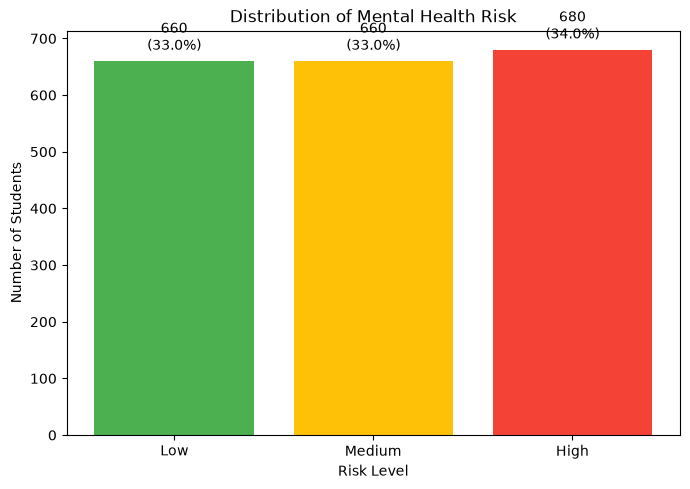

In [6]:
# Target variable analysis
target_variable_analysis(df)

NUMERICAL FEATURES HISTOGRAM


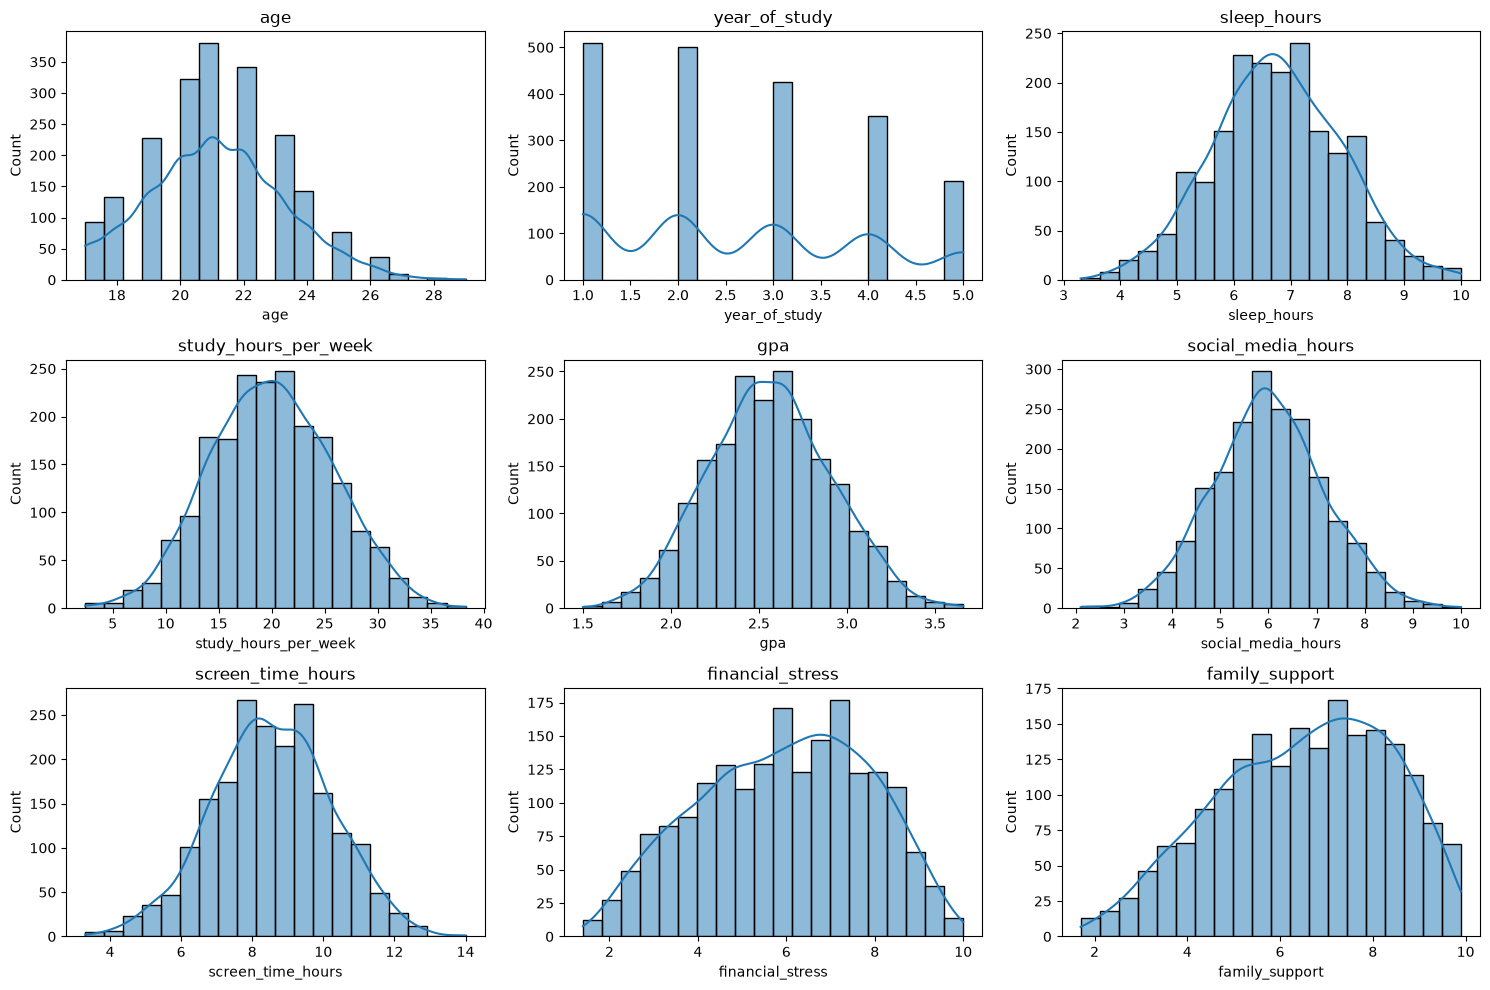

CATEGORICAL FEATURES BAR PLOT


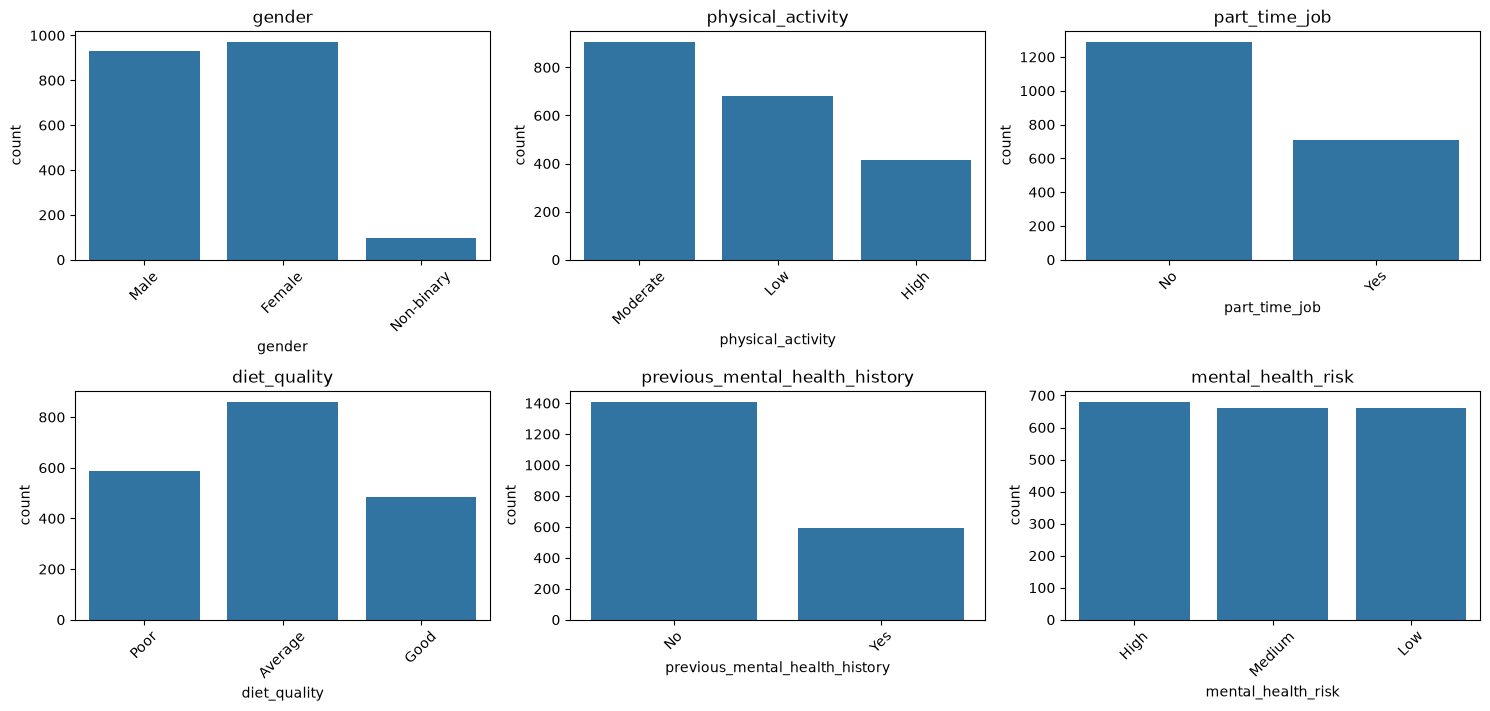

NUMERICAL FEATURES BOXPLOTS


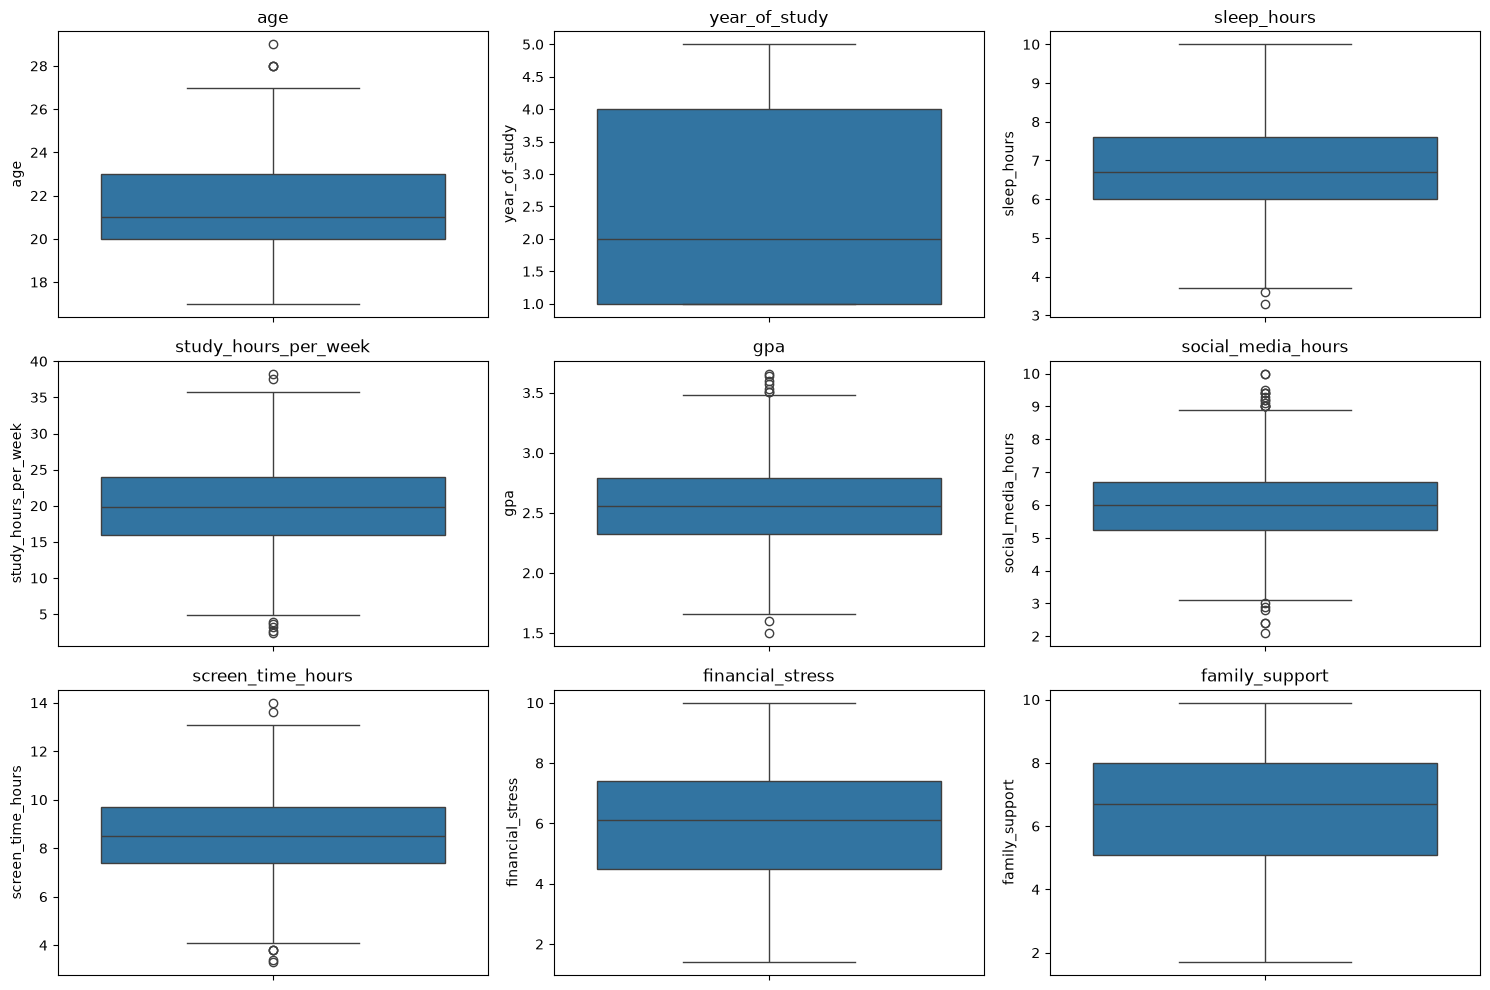

In [7]:
# Univariate analysis
univariate_analysis(df)

NUMERICAL FEATURES VS TARGET


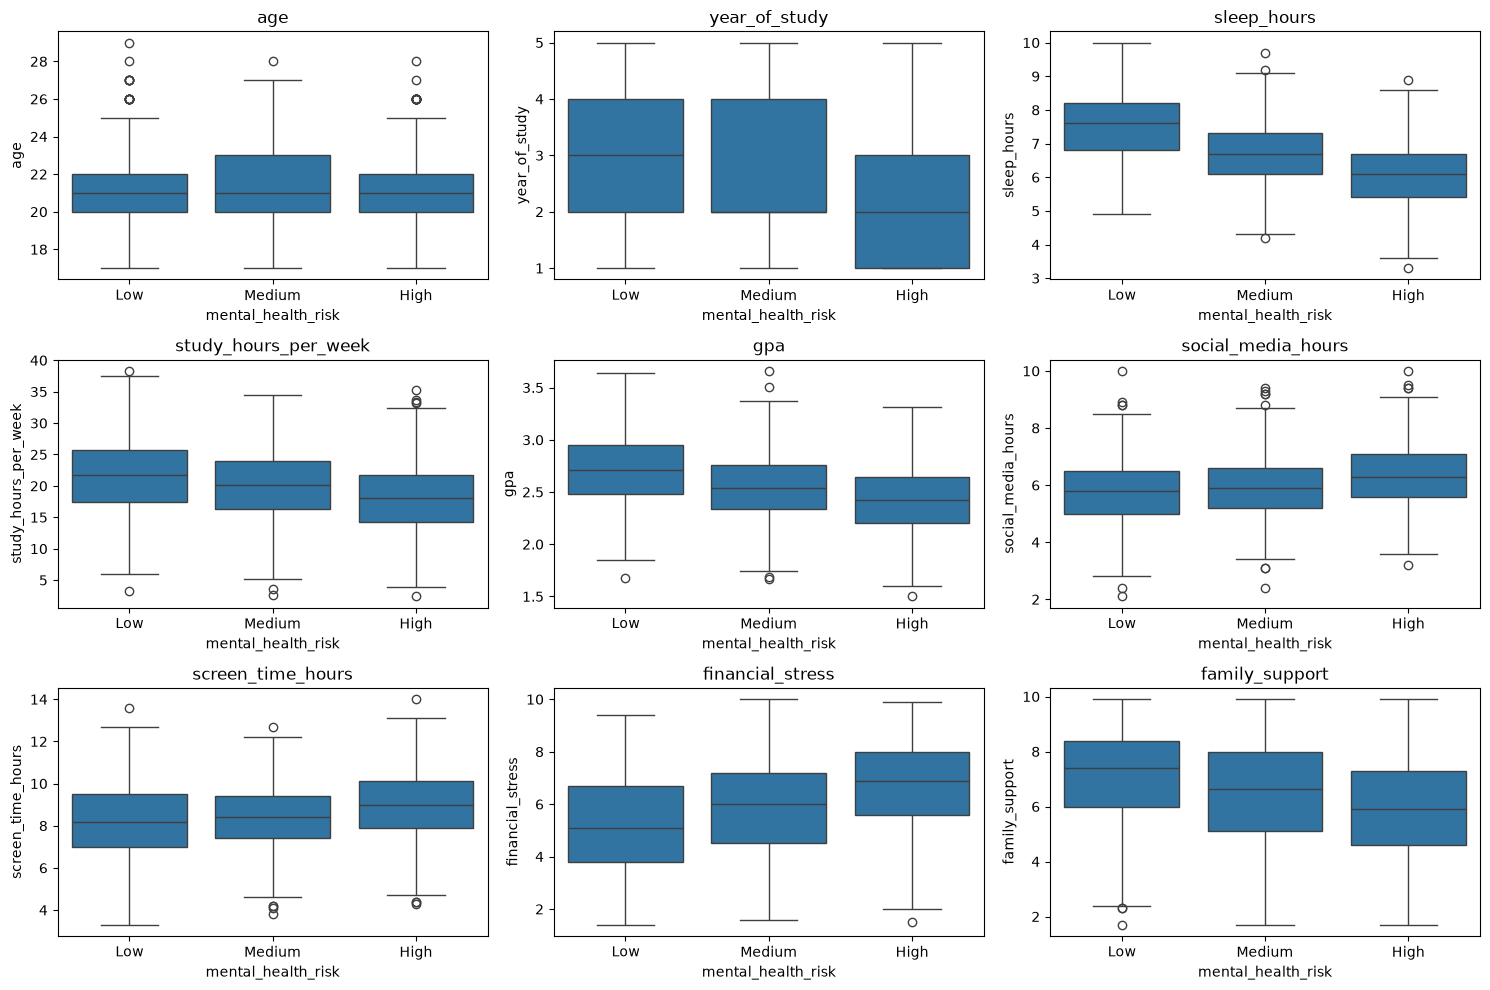

CATEGORICAL FEATURES VS TARGET


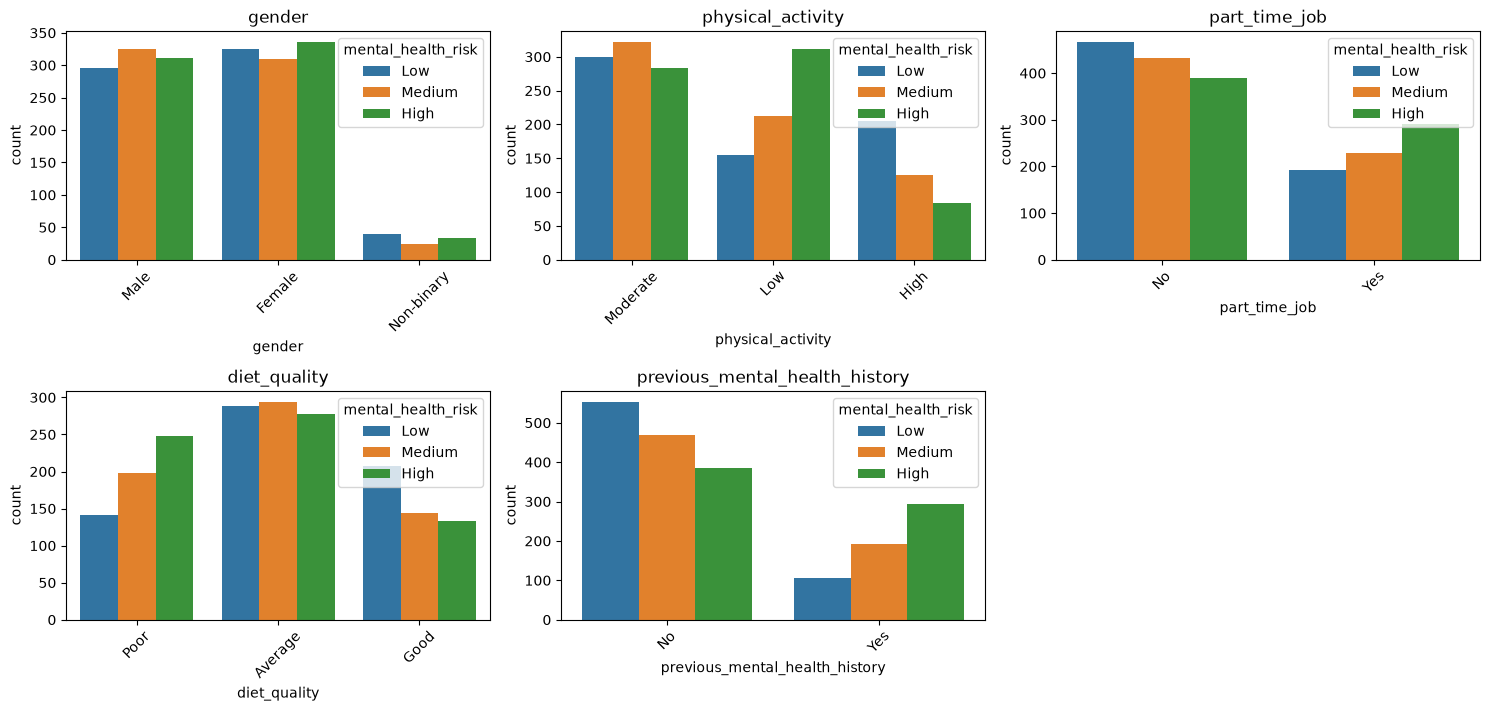

FEATURE RELATIONSHIPS


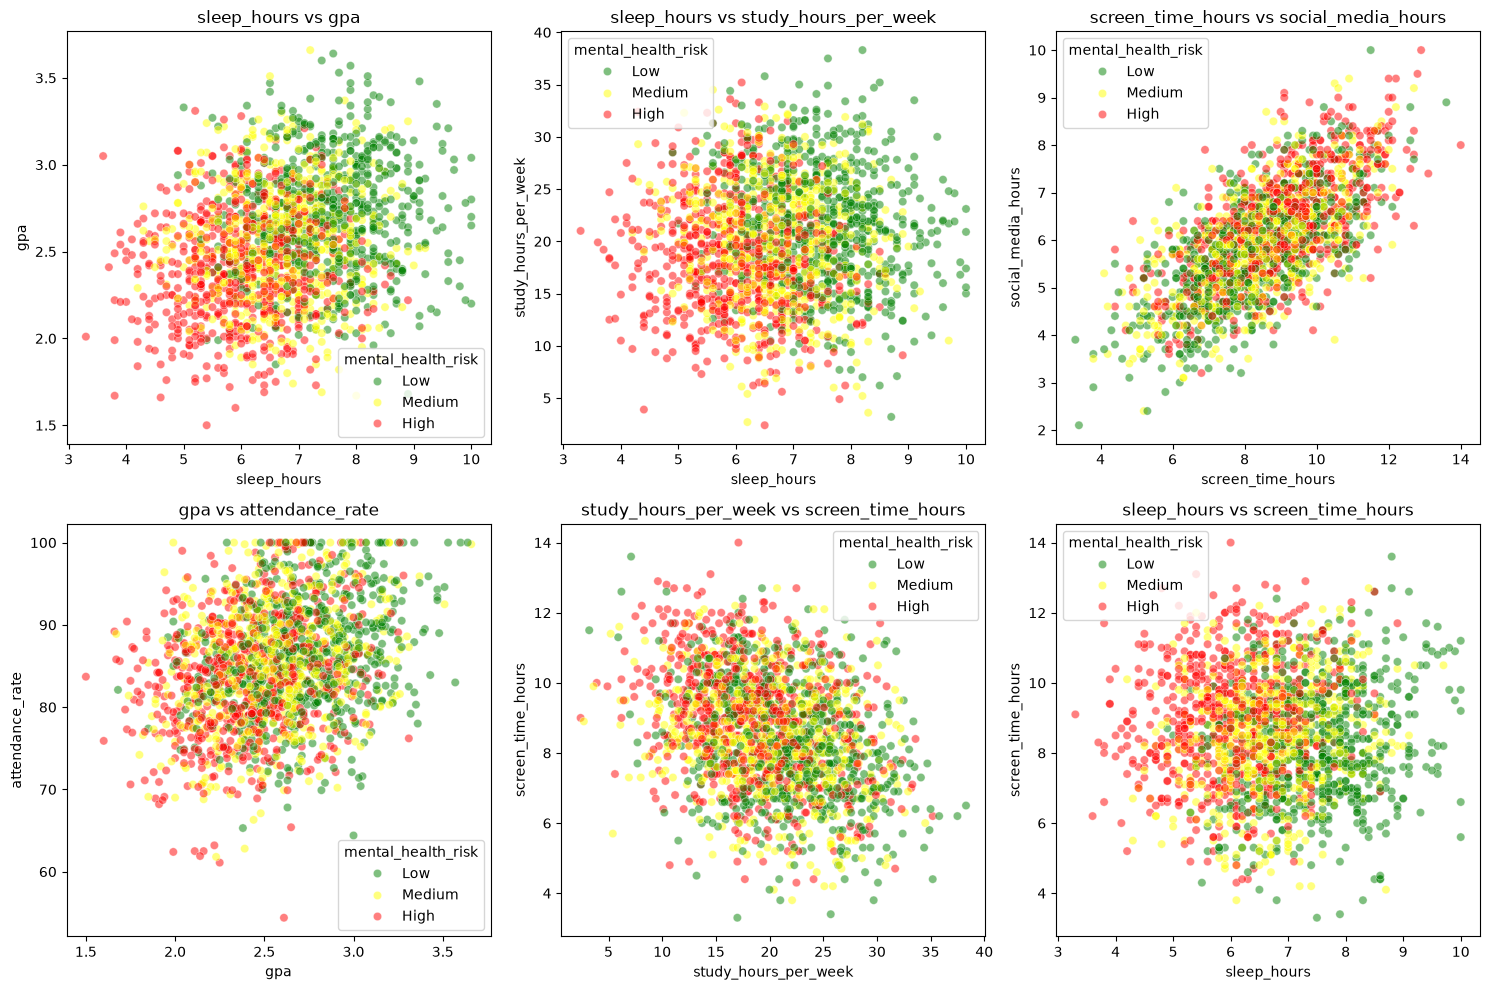

In [8]:
# Bevariate analysis
bevariate_analysis(df)

NUMERICAL FEATURE CORRELATION HEATMAP


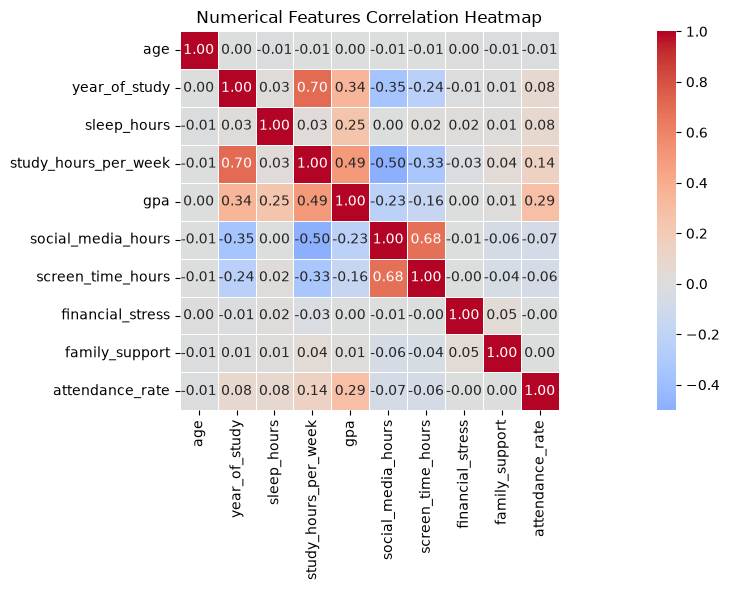

HIGHLY CORRELATED PAIRS (|corr| > 0.8):
NUMERICAL FEATURES VS TARGET
sleep_hours            -0.541857
gpa                    -0.352626
financial_stress        0.313547
family_support         -0.250894
study_hours_per_week   -0.238793
social_media_hours      0.207601
screen_time_hours       0.173972
year_of_study          -0.166404
attendance_rate        -0.145362
age                     0.004961
dtype: float64
CATEGORICAL FEATURES VS TARGET
student_id
student_id
STU0001    2.0
STU0002    1.0
STU0003    1.0
STU0004    2.0
STU0005    1.0
          ... 
STU1996    1.0
STU1997    2.0
STU1998    2.0
STU1999    0.0
STU2000    1.0
Name: mental_health_risk_num, Length: 2000, dtype: float64
gender
gender
Female        1.011329
Male          1.016094
Non-binary    0.938144
Name: mental_health_risk_num, dtype: float64
physical_activity
physical_activity
High        0.708434
Low         1.231222
Moderate    0.982340
Name: mental_health_risk_num, dtype: float64
part_time_job
part_time_job
No     0.

In [9]:
# Correlation and feature relevance
correlation_and_feature_relevance(df)

## Final EDA conclusions

### Data quality
- 2,000 rows, 17 columns (16 features + target `mental_health_risk`).
- Missing values are small, only in 7 columns: Financial_Stress ~4.5%, Diet_Quality ~3.5%, Sleep_Hours ~3.0%, Social_Media_Hours ~3.0%, Family_Support ~2.7%, Attendance_Rate ~2.4%, GPA ~1.9%.
- Duplicates: 0 rows.
- `student_id` is unique, no missing values.
- Inconsistency found: some rows have `social_media_hours > screen_time_hours`, which is impossible because social media time is part of total screen time. 37 rows.
- No impossible values for age, sleep, GPA, or attendance.
- IQR outliers exist mainly in `study_hours_per_week` and `screen_time_hours`, but very high study hours and very low sleep are realistic edge cases, not errors to delete.

### Target and features
- Target is balanced: Low ~660, Medium ~660, High ~680, about 33% each. No class imbalance, so SMOTE is probably not needed.
- No multicollinearity: no pair of numerical features has |corr| > 0.8.
- Strongest numerical features vs target (Low=0, Medium=1, High=2):
  - `sleep_hours` -0.54 — less sleep, higher risk
  - `gpa` -0.35 — lower GPA, higher risk
  - `financial_stress` +0.31 — more stress, higher risk
  - `family_support` -0.25 — less support, higher risk
  - `study_hours_per_week` -0.24, `social_media_hours` +0.21, `screen_time_hours` +0.17
  - `age` 0.005 — no link
- Strongest categorical features vs target (mean risk, 0=Low, 2=High):
  - `previous_mental_health_history`: Yes 1.32 vs No 0.88
  - `physical_activity`: Low 1.23, Moderate 0.98, High 0.71
  - `diet_quality`: Poor 1.18, Average 0.99, Good 0.85
  - `part_time_job`: Yes 1.14 vs No 0.94
  - `gender`: Female 1.01, Male 1.02, Non-binary 0.94 — no real difference

### Recommended preprocessing steps
1. Split first: 80/20 stratified split, `random_state=42`, stratify on `mental_health_risk`.
2. Drop `student_id`, it is only an ID.
3. Imputation, fit on train only: mean for numerical columns, mode for categorical columns.
4. Cap `social_media_hours` at `screen_time_hours`.
5. Encoding: ordinal for `physical_activity` (Low/Moderate/High) and `diet_quality` (Poor/Average/Good), one-hot for `gender`, binary for `part_time_job` and `previous_mental_health_history`.
6. Scaling: `StandardScaler` for numerical features, fit on train only, inside a pipeline to avoid leakage.
7. Outliers: keep realistic extremes, cap only clear IQR outliers for `study_hours_per_week` and `screen_time_hours`.
8. No SMOTE, classes are balanced.
